In [1]:
using CairoMakie
CairoMakie.activate!()
Makie.inline!(true)

true

In [2]:
4*(1-1/3+1/5-1/7+1/9-1/11+1/13-1/15+1/17-1/19)

3.0418396189294032

In [3]:
function calcPi(n::Integer)
  n > 0 || throw(ArgumentError("The input n must be positive."))
  local sum = 1.0
  for k=1:n
    sum += (-1)^k/(2k+1)
  end
  4*sum
end


calcPi (generic function with 1 method)

In [4]:
pi10_000 = calcPi(10_000)

3.1416926435905346

In [5]:
absErr(x::Real)=abs(x-pi)

absErr (generic function with 1 method)

In [6]:
absErr(pi10_000)

9.99900007414567e-5

In [7]:
errors = map(n->absErr(calcPi(10^n)),1:7)

7-element Vector{Float64}:
 0.09072315581580082
 0.009900747481198291
 0.0009990007497511222
 9.99900007414567e-5
 9.999899927226608e-6
 9.999989813991306e-7
 9.999998829002266e-8

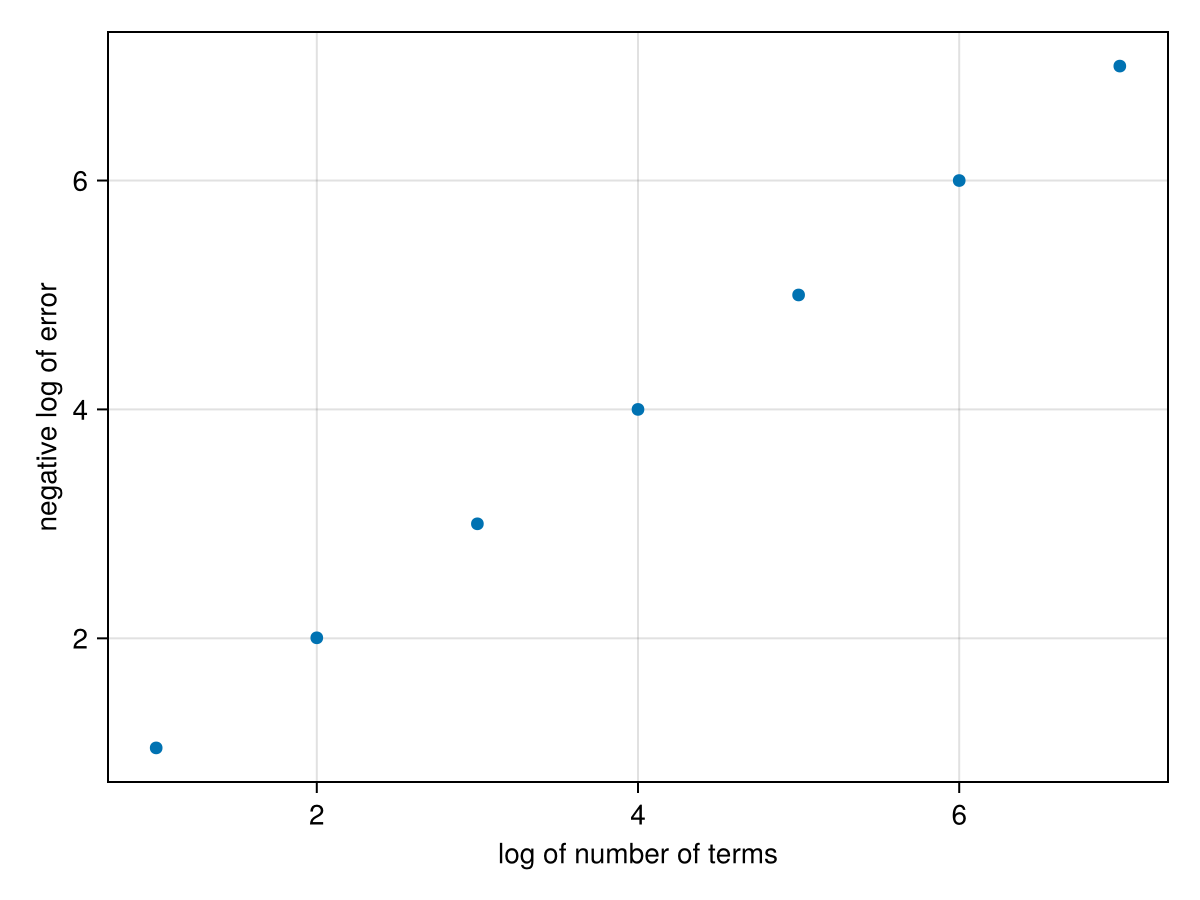

In [8]:
fig = Figure()
ax = Axis(fig[1,1], xlabel = "log of number of terms", ylabel = "negative log of error")
scatter!(ax, 1:7,-log10.(errors))
fig


In [9]:
save("../../assets/plots/calc-pi/pi-atan-error.png", fig)

In [10]:
@time calcPi(1_000_000)

  0.036164 seconds


3.1415936535887745

In [11]:
0.077268 * 10^14 /60/60/24/365

245015.2207001522

In [12]:
function atan_series(x::Real,n::Integer)
  n > 0 || throw(ArgumentError("The input n must be positive."))
  local sum = x
  for k=1:n
    sum += (-1)^k*x^(2k+1)/(2k+1)
  end
  sum
end

atan_series (generic function with 1 method)

In [13]:
4*(atan_series(1/2,10)+atan_series(1/3,10))

3.1415926704506854

In [14]:
absErr(4*(atan_series(1/2,10)+atan_series(1/3,10)))

1.6860892237957614e-8

In [15]:
absErr(4*(atan_series(1/2,20)+atan_series(1/3,20)))

7.993605777301127e-15

In [16]:
4*(atan_series(1/big(2),20)+atan_series(1/big(3),20))

3.141592653589801775394859982612606961085892242193168775435423632752985359741545

In [17]:
errors2=map(n -> absErr(4*(atan_series(1/big(2), 10n) + atan_series(1/big(3), 10n))), 1:5)

5-element Vector{BigFloat}:
 1.686089269049955549324338738573041181676956757596130409476023763757476121934317e-8
 8.536932216599333104076888722842818062954460479040445168953455346681077569196179e-15
 5.541360098004753291440085860743946761847969162268014510791810751138256936210001e-21
 4.005347048909364704518520476811412326265959273017889120734252574465535050431139e-27
 3.075296346725383632749782433311833539450331895967037047902902585859740513243069e-33

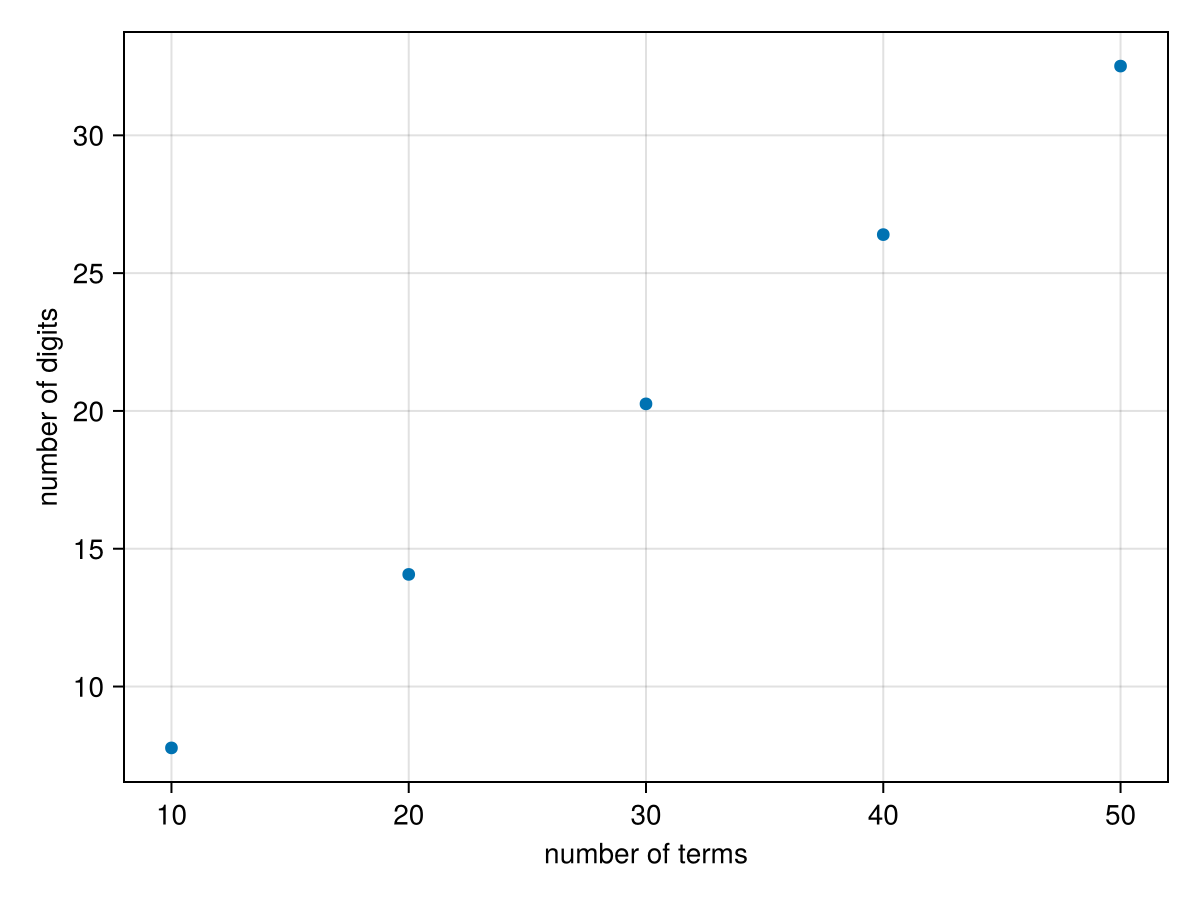

In [18]:
fig = Figure()
ax = Axis(fig[1,1], xlabel="number of terms", ylabel="number of digits")
scatter!(ax, 10:10:50, -log10.(errors2))
fig

In [19]:
save("../../assets/plots/calc-pi/error-euler.png",fig)

In [20]:
@time absErr(4*(atan_series(1/big(2),100)+atan_series(1/big(3),100)))

  0.000095 seconds (1.01 k allocations: 88.438 KiB)


1.228611811943582079576172348238260677444453102891747999520879961795376821279531e-63

In [21]:
absErr(4*(atan_series(1/big(2),100)+atan_series(1/big(3),100)))

1.228611811943582079576172348238260677444453102891747999520879961795376821279531e-63

In [22]:
precision(4*(atan_series(1/big(2),100)+atan_series(1/big(3),100)))

256

In [23]:
log10(2)

0.3010299956639812

In [24]:
setprecision(4096) do
  print(length(string(1/big(3))))
end

1237

In [25]:
pi1000 = nothing
setprecision(4096) do
  pi1000=4*(atan_series(1/big(2),1594)+atan_series(1/big(3),1594))
  absErr(pi1000)
end

2.59753510954587549041954911578576968036221315072936349312950931876487384192401926677097525464278225299414684505498777136669660116148513136006695968861964989941439216721754591082904719608634594616392512916622323685658962463281205982609391064634574796309171744837612185612101204128694651765250058248078994384811963299937904933599005224547594823182022661059213312490079780977757246879563016426335508606371749241902283998426316148796391580469170426352910426319652918451665270362034523198131782960829298949007348807405472694328289979618164034441631663545144846999773632841776232901221840207501789328736249335700746828729427230764498795408649476985244226324790566308930085994284695623644947687903257440310119306015963290860262892421101793412793932009293146602730310574730819130786927986914991625551144944447419758030329746237399190312380866556852808327589808717954196988226808255292397501893694733478472519641951247067462448611333220383790605839159766360694555187816095724378641783866218065689572174814658

In [26]:
numDigits(pi_approx::Real) = floor(Int,-log10(absErr(pi_approx)))

numDigits (generic function with 1 method)

In [27]:
setprecision(4096) do
  @show pi1000=4*(atan_series(1/big(2),1594)+atan_series(1/big(3),1594))
  numDigits(pi1000)
end

pi1000 = 4 * (atan_series(1 / big(2), 1594) + atan_series(1 / big(3), 1594)) = 3.1415926535897932384626433832795028841971693993751058209749445923078164062862089986280348253421170679821480865132823066470938446095505822317253594081284811174502841027019385211055596446229489549303819644288109756659334461284756482337867831652712019091456485669234603486104543266482133936072602491412737245870066063155881748815209209628292540917153643678925903600113305305488204665213841469519415116094330572703657595919530921861173819326117931051185480744623799627495673518857527248912279381830119491298336733624406566430860213949463952247371907021798609437027705392171762931767523846748184676694051320005681271452635608277857713427577896091736371787214684409012249534301465495853710507922796892589235420199561121290219608640344181598136297747713099605187072113499999983729780499510597317328160963185950244594553469083026425223082533446850352619311881710100031378387528865875332083814206171776691473035982534904287554687

963

In [28]:
@time setprecision(4096) do
  pi1000=4*(atan_series(1/big(2),1700)+atan_series(1/big(3),1700))
  numDigits(pi1000)
end

  0.105931 seconds (61.60 k allocations: 10.834 MiB, 71.63% gc time, 8.69% compilation time)


1027

### Speeding up ArcTangent

In [29]:
function atan_series2(x::T, n::Integer) where T<:Real
    n > 0 || throw(ArgumentError("The input n must be positive."))
    local negxsq = -x^2
    local sum = one(T)
    local ak = one(T)
    local denom = 1
    for k=2:n
        ak *= negxsq
        denom += 2
        sum += ak/denom
    end
    x*sum
end

atan_series2 (generic function with 1 method)

In [30]:
using BenchmarkTools

In [31]:
@btime setprecision(2^14) do
  numDigits(4*(atan_series(1/big(2),1700)+atan_series(1/big(3),1700)))
end

  175.147 ms (57861 allocations: 42.38 MiB)


1027

In [32]:
@btime setprecision(2^14) do
  numDigits(4*(atan_series2(1/big(2),1700)+atan_series2(1/big(3),1700)))
end

  17.832 ms (40877 allocations: 25.58 MiB)


1026

In [33]:
b_mil = (1_000_000-1)/log10(2)

3.3219247729592673e6

In [34]:
log(b_mil)/log(2)

21.66358797227303

In [35]:
@time setprecision(2^22) do
  numDigits(4*(atan_series2(1/big(2),100)+atan_series2(1/big(3),100)))
end

  5.549939 seconds (181.17 k allocations: 5.551 GiB, 3.67% gc time, 0.15% compilation time)


62

In [36]:
@time setprecision(2^22) do
  numDigits(4*(atan_series2(1/big(2),200)+atan_series2(1/big(3),200)))
end

  4.404048 seconds (122.58 k allocations: 5.065 GiB, 2.45% gc time, 0.19% compilation time)


122

In [37]:
1_000_000/63 * 5.979 / 60 /60

26.362433862433864

### Machin's Formulae

In [38]:
function machin(coeffs::Vector{Int}, xvals::Vector{T},n::Int) where T <: Integer
  length(coeffs) == length(xvals) || throw(ArgumentError("The lengths of the vectors must match"))
  local sum=zero(BigFloat)
  for i=1:length(coeffs)
    sum += coeffs[i]*atan_series2(1/big(xvals[i]),n)
  end
  4*sum
end

machin (generic function with 1 method)

In [39]:
@time setprecision(2^14) do
  numDigits(machin([1,1],[2,3],100))
end

  0.018588 seconds (24.82 k allocations: 2.704 MiB, 88.82% compilation time)


62

In [40]:
@time setprecision(2^22) do
  numDigits(machin([1,1],[2,3],100))
end

  3.392750 seconds (112.20 k allocations: 3.701 GiB, 2.93% gc time, 0.31% compilation time)


62

In [41]:
@time setprecision(2^22) do
  numDigits(machin([4,-1],[5,239], 100))
end

  4.339856 seconds (116.79 k allocations: 4.400 GiB, 2.28% gc time, 0.22% compilation time)


141

In [42]:
@time setprecision(2^22) do
  numDigits(machin([4,-1],[5,239], 200))
end

  6.417789 seconds (130.22 k allocations: 6.484 GiB, 0.38% gc time, 0.15% compilation time)


281

In [43]:
@time setprecision(2^22) do
  numDigits(machin([4,-1],[5,239], 400))
end

 10.388933 seconds (157.03 k allocations: 10.652 GiB, 1.12% gc time, 0.09% compilation time)


561

In [44]:
@time setprecision(2^22) do
  numDigits(machin([4,-1],[5,239], 800))
end

 18.130449 seconds (210.59 k allocations: 18.985 GiB, 0.69% gc time, 0.05% compilation time)


1121

In [45]:
@time setprecision(2^22) do
  numDigits(machin([4,-1],[5,239], 1600))
end

 33.863660 seconds (317.79 k allocations: 35.654 GiB, 0.40% gc time, 0.03% compilation time)


2239

In [46]:
1_000_000/2239 * 37.205 /60 / 60

4.615775892015284

### Takano's method

In [47]:
@time setprecision(2^22) do
  numDigits(machin([44,7,-12,24],[57,239,682,12943], 100))
end

  6.174685 seconds (132.28 k allocations: 6.539 GiB, 0.20% gc time, 0.16% compilation time)


352

In [48]:
@time setprecision(2^22) do
  numDigits(machin([12,32,-5,12],[49,57,239,110443], 100))
end

  6.203508 seconds (132.27 k allocations: 6.539 GiB, 0.20% gc time, 0.15% compilation time)


340

In [49]:
@time setprecision(2^22) do
  numDigits(machin([12,32,-5,12],[49,57,239,110443], 200))
end

 10.230121 seconds (159.07 k allocations: 10.706 GiB, 0.95% gc time, 0.09% compilation time)


678

In [50]:
1_000_000/678 * 11.034991 /60/60

4.521054981973124

### Parker's method

In [51]:
@time setprecision(2^22) do
  numDigits(machin([83,17,-22,-24,-44,12,22],
    [big(107),big(1710),big(103697),big(2513489),big(18280007883),big(7939642926390344818), big(3054211727257704725384731479018)], 100))
end

  9.223725 seconds (240.14 k allocations: 9.751 GiB, 0.17% gc time, 0.34% compilation time)


407

In [52]:
@time setprecision(2^22) do
  numDigits(machin([83,17,-22,-24,-44,12,22],
    [big(107),big(1710),big(103697),big(2513489),big(18280007883),big(7939642926390344818), big(3054211727257704725384731479018)], 200))
end

 16.117153 seconds (242.06 k allocations: 17.042 GiB, 0.13% gc time, 0.09% compilation time)


813

In [53]:
@time setprecision(2^22) do
  numDigits(machin([83,17,-22,-24,-44,12,22],
    [big(107),big(1710),big(103697),big(2513489),big(18280007883),big(7939642926390344818), big(3054211727257704725384731479018)], 400))
end

 30.189407 seconds (335.88 k allocations: 31.627 GiB, 0.39% gc time, 0.05% compilation time)


1625

In [54]:
1_000_000/813 *31.81/60/60

10.868525351920187

In [55]:
function chud(n::Integer)
  sum = big(0)
  for k=0:n
    ak =  (-1)^k*factorial(big(6k))/factorial(big(3k))/ factorial(big(k))^3/ (big(640320)^3)^(k+0.5)
    sum += big(545140134)*k*ak + big(13591409)*ak
  end
  1/(12sum)
end

chud (generic function with 1 method)

In [56]:
@time setprecision(2^22) do
  numDigits(chud(20))
end

 59.591682 seconds (1.74 M allocations: 53.628 GiB, 0.38% gc time, 0.03% compilation time)


297

In [57]:
function chudnovsky(n::Integer)
  local sum1 = big(1.0)
  local sum2 = big(0.0)
  local top = big(1)
  local bottom = big(1)
  local C = big(640320)^3
  for k=1:n
    top *= -24*(6*k-5)*(2*k-1)*(6*k-1)
    bottom *= C*k^3
    sum1 += top/bottom
    sum2 += k * top/bottom
  end
  426880*sqrt(big(10005))/(13591409*sum1 + 545140134*sum2)
end

chudnovsky (generic function with 1 method)

In [58]:
numDigits(chudnovsky(1))

27

In [59]:
@time setprecision(2^22) do
  numDigits(chudnovsky(20))
end

  3.058575 seconds (166.45 k allocations: 3.341 GiB, 0.28% gc time, 0.26% compilation time)


297

In [60]:
@time setprecision(2^22) do
  numDigits(chudnovsky(40))
end

  3.888012 seconds (205.09 k allocations: 4.368 GiB, 0.16% gc time, 0.18% compilation time)


581

In [61]:
@time setprecision(2^22) do
  numDigits(chudnovsky(80))
end

  5.520722 seconds (282.45 k allocations: 6.423 GiB, 0.15% gc time, 0.12% compilation time)


1148

In [62]:
1_000_000/1148 * 5.7/60/60

1.3792102206736354

In [63]:
@time setprecision(2^22) do
  numDigits(chudnovsky(200))
end

 10.504804 seconds (514.52 k allocations: 12.589 GiB, 0.10% gc time, 0.06% compilation time)


2850

In [64]:
1_000_000/2850 * 11.08/60/60

1.0799220272904484

## Binary Splitting Algorithm applied to the Chudnovsky Series

In [65]:
function binary_split(a::Integer, b::Integer, init::Function)
    if b - a == 1
        return init(a)
    else
        m = (a + b) ÷ 2
        left = binary_split(a, m, init)
        right = binary_split(m, b, init)
        return (P=left.P*right.P, Q=left.Q*right.Q, T=left.T * right.Q + left.P * right.T)
    end
end

binary_split (generic function with 1 method)

In [66]:
big_c = big(640320)^3 ÷ 24
a0 = big(545140134)
a1 = big(13591409)
function chud_terms(k::Integer)
  if k == 0
    return (P=1, Q=1, T=a1)
  else
    P = big((6k-5)*(2k-1)*(6k-1))
    return (P=P, Q=big(k)^3 * big_c, T= (isodd(k) ? -1 : 1) * P*(a0*k+a1))
  end
end

chud_terms (generic function with 1 method)

In [67]:
binary_split(0,1, chud_terms), binary_split(1,2,chud_terms)

((P = 1, Q = 1, T = 13591409), (P = 5, Q = 10939058860032000, T = -2793657715))

In [69]:
factorial(6)*(a0*1+a1)//(factorial(3)*factorial(1)^3*(640320^3)), 2793657715//10939058860032000

(558731543//2187811772006400, 558731543//2187811772006400)

In [74]:
term4 = binary_split(0,2,chud_terms)
pi_approx = 426880*sqrt(big(10005))/(term4.T/term4.Q)

3.141592653589793238462643383587350688475866345996374315654905806801301450565177

In [75]:
numDigits(pi_approx)

27

In [93]:
let
    terms = @btime binary_split(0, 2^16, chud_terms)
    pi_approx = @btime BigFloat(426880*sqrt(big(10005))/($terms.T/$terms.Q), precision=2^22)
    @show precision(pi_approx)
    numDigits(pi_approx)
end


  177.452 ms (2623403 allocations: 175.29 MiB)
  306.816 ms (5869 allocations: 297.56 MiB)
precision(pi_approx) = 4194304


929409

In [ ]:
term4 = binary_split(0,4,chud_terms)

(P = 1276275, Q = 282744150338349327484720295874090277797888000000000, T = 3842891389605921886462458445812845012126032377429502755975)

In [65]:
p2 = big(426880) * sqrt(big(10005)) * term2.Q / term2.T

3.141592653589793238462643383279502884197169399375105820984947408020662452789705

In [68]:
 numDigits(p2)

55

In [66]:
numDigits(p2)

55

In [77]:
@time setprecision(2^24) do
  terms = binary_split(0,2^18, chud_terms)
  p2 = big(426880) * sqrt(big(10005)) * terms.Q / terms.T
  numDigits(p2)
end

 26.060256 seconds (11.28 M allocations: 23.752 GiB, 0.45% gc time, 0.04% compilation time)


3717635

In [33]:
-1*factorial(big(6))*(a0*1+a1) // (factorial(3) * 1 * big(640320)^3)

-558731543//2187811772006400

In [34]:
binary_split(1,2,chud_terms).T // binary_split(1,2,chud_terms).Q

-558731543//2187811772006400

In [44]:
binary_split(0,1,chud_terms).T // binary_split(0,1,chud_terms).Q + 
binary_split(1,2,chud_terms).T // binary_split(1,2,chud_terms).Q

29735444608353174286057//2187811772006400

In [45]:
binary_split(0,2, chud_terms).T // binary_split(0,2, chud_terms).Q

29735444608353174286057//2187811772006400

In [122]:
using Distributed
addprocs(4)

4-element Vector{Int64}:
 5
 6
 7
 8

In [124]:
@everywhere function paraChud(n1::Integer,n2::Integer,prec::Integer)
  setprecision(prec)
  local C = big(640320)^3
  local bottom = big(1)
  local top = big(1)
  for k=1:n1
    bottom *= k^3*C
    top *= -8*(6k-1)*(6k-3)*(6k-5)
  end
  local sum1 = n1*top/bottom
  local sum2 = top/bottom
  for k=n1+1:n2
    bottom *= k^3*C
    top *= -8*(6k-1)*(6k-3)*(6k-5)
    sum1 += k*top/bottom
    sum2 += top/bottom
  end
  545140134*sum1 + 13591409*sum2
end

In [110]:
@time let
  prec = 2^22
  p1 = paraChud(0,9,prec)
  p2 = paraChud(10,19,prec)
  p3 = paraChud(20,29,prec)
  p4 = paraChud(30,39,prec)
  numDigits(sqrt(big(640320)^3)/(12*(p1+p2+p3+p4)))
end

  4.203828 seconds (168.46 k allocations: 4.365 GiB, 1.34% gc time, 0.05% compilation time)


567

In [116]:
@time setprecision(2^22) do
  local p = pmap(i->paraChud(10*(i-1),10i-1,2^22),1:4)
  local s = sum(p)
  numDigits(sqrt(big(640320)^3)/(12s))
end

  3.433289 seconds (400.80 k allocations: 2.325 GiB, 2.75% gc time, 4.31% compilation time)


567

In [125]:
@time setprecision(2^22) do
  local p = pmap(i -> paraChud(10*(i-1), 10i-1, 2^22),1:8)
  local s = sum(p)
  numDigits(sqrt(big(640320)^3)/(12s))
end

  3.445605 seconds (403.21 k allocations: 2.328 GiB, 2.29% gc time, 3.20% compilation time)


1134

In [126]:
@time setprecision(2^22) do
  local p = pmap(i->paraChud(50*(i-1),50i-1,2^22),1:8)
  local s = sum(p)
  numDigits(sqrt(big(640320)^3)/(12s))
end

  7.902904 seconds (402.03 k allocations: 2.327 GiB, 0.40% gc time, 1.15% compilation time)


5672

In [127]:
@time setprecision(2^22) do
  local p = pmap(i->paraChud(100*(i-1),100i-1,2^22),1:8)
  local s = sum(p)
  numDigits(sqrt(big(640320)^3)/(12s))
end

 12.936252 seconds (402.29 k allocations: 2.327 GiB, 0.10% gc time, 0.40% compilation time)


11345

In [128]:
1_000_000/11345 *12.93 /60

18.995152049360954

In [121]:
nprocs()

4

In [139]:
@everywhere function chud_chunk_fast(n1::Int, n2::Int, prec::Int)
    setprecision(BigFloat, prec)
    
    # Chudnovsky constant: 640320^3 / 24 = 10939058860032000
    C3_OVER_24 = big(640320)^3 ÷ 24
    
    # 1. Compute starting term A_{n1} directly (seed term)
    # A_k = (-1)^k * (6k)! / ((3k)! * (k!)^3 * (640320)^(3k))
    Ak = (-1)^n1 * factorial(big(6n1)) / (factorial(big(3n1)) * factorial(big(n1))^3 * big(640320)^(3n1))
    
    # Compute initial sum component for k = n1
    # Term_k = Ak * (13591409 + 545140134 * k)
    total_sum = Ak * (13591409 + 545140134big(n1))
    
    # 2. Build remaining terms sequentially inside this worker's chunk
    for k in (n1 + 1):n2
        # Ratio update: Ak = Ak * [ -(6k-5)(2k-1)(6k-1) / (k^3 * C3_OVER_24) ]
        num_factor = -big(6k - 5) * (2k - 1) * (6k - 1)
        den_factor = big(k)^3 * C3_OVER_24
        
        Ak = (Ak * num_factor) / den_factor
        
        # Accumulate
        total_sum += Ak * (13591409 + 545140134big(k))
    end
    
    return total_sum
end

In [140]:
function compute_pi_pmap(total_terms::Int, prec::Int)
    setprecision(BigFloat, prec)
    
    # 1. Divide range into chunks matching worker count
    w = nworkers()
    chunk_size = total_terms ÷ w
    
    ranges = [(i == 1 ? 0 : (i-1)*chunk_size + 1, 
               i == w ? total_terms : i*chunk_size) 
              for i in 1:w]
    
    # 2. Distribute work across processes using pmap
    partial_sums = pmap(r -> chud_chunk_fast(r[1], r[2], prec), ranges)
    
    # 3. Combine partial sums and complete final Chudnovsky formula
    S = sum(partial_sums)
    C = big(426880) * sqrt(big(10005))
    
    return C / S
end

compute_pi_pmap (generic function with 1 method)

In [141]:
@time numDigits(compute_pi_pmap(800,2^22))

  2.987587 seconds (230.63 k allocations: 2.322 GiB, 2.80% gc time, 1.76% compilation time)


11359

In [146]:
@time numDigits(compute_pi_pmap(100_000,2^22))

 18.803612 seconds (90.21 k allocations: 2.318 GiB, 0.37% gc time)


1262609

In [145]:
@time numDigits(compute_pi_pmap(200_000,2^23))

 83.303461 seconds (269.73 k allocations: 9.187 GiB, 0.18% gc time)


2525220

In [147]:
using Distributed

@everywhere struct ChudBlock
    P::BigInt
    Q::BigInt
    T::BigInt
end

# Pure integer range evaluation - NO factorials, NO floats, NO redundant work!
@everywhere function bs_range(a::Int, b::Int)
    if b - a == 1
        if a == 0
            return ChudBlock(big(1), big(1), big(13591409))
        else
            P = big(6a - 5) * (2a - 1) * (6a - 1)
            Q = big(a)^3 * (big(640320)^3 ÷ 24)
            T = P * (13591409 + 545140134big(a))
            isodd(a) && (T = -T)
            return ChudBlock(P, Q, T)
        end
    else
        m = (a + b) ÷ 2
        left = bs_range(a, m)
        right = bs_range(m, b)
        
        # Merge sub-trees using integer arithmetic
        P = left.P * right.P
        Q = left.Q * right.Q
        T = left.T * right.Q + left.P * right.T
        return ChudBlock(P, Q, T)
    end
end

In [158]:
bs_range(0,1), bs_range(1,2)

(ChudBlock(1, 1, 13591409), ChudBlock(5, 10939058860032000, -2793657715))

In [159]:
function pi_binary_split(terms::Int, prec::Int)
    setprecision(BigFloat, prec)
    
    # 1. Divide [0, terms] into equal chunks for each worker
    w = nworkers()
    chunk_size = div(terms, w)
    ranges = [(i == 1 ? 0 : (i-1)*chunk_size, i == w ? terms : i*chunk_size) for i in 1:w]
    
    # 2. Worker processes build integer blocks independently in parallel
    blocks = pmap(r -> bs_range(r[1], r[2]), ranges)
    @show blocks
    
    # 3. Combine partial blocks sequentially on the main node
    final_block = foldl((l, r) -> ChudBlock(
        l.P * r.P,
        l.Q * r.Q,
        l.T * r.Q + l.P * r.T
    ), blocks)
    
    # 4. Perform a SINGLE BigFloat division at the very end
    C = big(426880) * sqrt(big(10005))
    return (final_block.Q * C) / final_block.T
end

pi_binary_split (generic function with 1 method)

In [154]:
@time numDigits(pi_binary_split(80_000, 2^22))

  3.039671 seconds (92.73 k allocations: 2.447 GiB, 0.27% gc time)


1134533

In [161]:
pi_binary_split(4,2^22)

      From worker 2:	Warning: detected a stack overflow; program state may be corrupted, so further execution might be unreliable.
      From worker 3:	Warning: detected a stack overflow; program state may be corrupted, so further execution might be unreliable.
      From worker 4:	Warning: detected a stack overflow; program state may be corrupted, so further execution might be unreliable.
      From worker 6:	Warning: detected a stack overflow; program state may be corrupted, so further execution might be unreliable.
      From worker 7:	Warning: detected a stack overflow; program state may be corrupted, so further execution might be unreliable.
      From worker 5:	Warning: detected a stack overflow; program state may be corrupted, so further execution might be unreliable.


LoadError: On worker 2:
StackOverflowError:
Stacktrace:
      [1] [0m[1mbs_range[22m
 [90m       @[39m [90m./[39m[90m[4mIn[147]:10[24m[39m
 [90m┌[39m    [2] [0m[1mbs_range[22m
 [90m│[39m[90m      @[39m [90m./[39m[90m[4mIn[147]:23[24m[39m
[90m ╰───────[39m[90m[3m repeated 47463 times[23m[39m
  [47465] [0m[1m#pi_binary_split##8[22m
 [90m       @[39m [90m./[39m[90m[4mnone:-1[24m[39m[90m [inlined][39m
  [47466] [0m[1m#exec_from_cache#152[22m
 [90m       @[39m [90m~/.julia/juliaup/julia-1.13.1+0.aarch64.apple.darwin14/Julia-1.13.app/Contents/Resources/julia/share/julia/stdlib/v1.13/Distributed/src/[39m[90m[4mworkerpool.jl:390[24m[39m
  [47467] [0m[1mexec_from_cache[22m
 [90m       @[39m [90m~/.julia/juliaup/julia-1.13.1+0.aarch64.apple.darwin14/Julia-1.13.app/Contents/Resources/julia/share/julia/stdlib/v1.13/Distributed/src/[39m[90m[4mworkerpool.jl:388[24m[39m
  [47468] [0m[1m#handle_msg##4[22m
 [90m       @[39m [90m~/